# 05 · DiMA workflow for the implemented perturbations (A6, Module 2)
**Paper:** Lamoureux et al. 2023, Fig. 6, "apply the knowledge base to new data": new samples are projected onto the PRECISE-1K
iModulons (pseudoinverse of **M**) and compared with differential iModulon activity (DiMA).

1. Reproduce the paper's own case (anaerobic → aerobic transition, AAT).
2. Define the perturbations (`src/perturbation.py`, `config/precise1k_condition_map.yaml`).
3. Simulate each perturbation and its control with the A5 calibrated circuit, turn the populations into pseudo-bulk samples,
   and run the same DiMA against the matched real PRECISE-1K / K-12 condition.

In [1]:
import sys, json, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '../src')
from pathlib import Path
import pandas as pd, yaml
from IPython.display import Image, display
ROOT = Path('..'); A6 = ROOT/'outputs'/'a6'
pd.set_option('display.width', 200)

## 1 · Reproduce Fig. 6 (AAT vs PRECISE-1K)

In [2]:
import a6_reproduce_aat
chk = a6_reproduce_aat.main()
print('paper DiMAs reproduced:', len(chk['overlap']), 'of', len(chk['paper_significant']),
      '| max |difference| error:', round(chk['max_abs_diff_vs_paper'], 3), '| extra:', chk['only_ours'])

paper DiMAs reproduced: 11 of 11 | max |difference| error: 0.016 | extra: ['Putrescine']


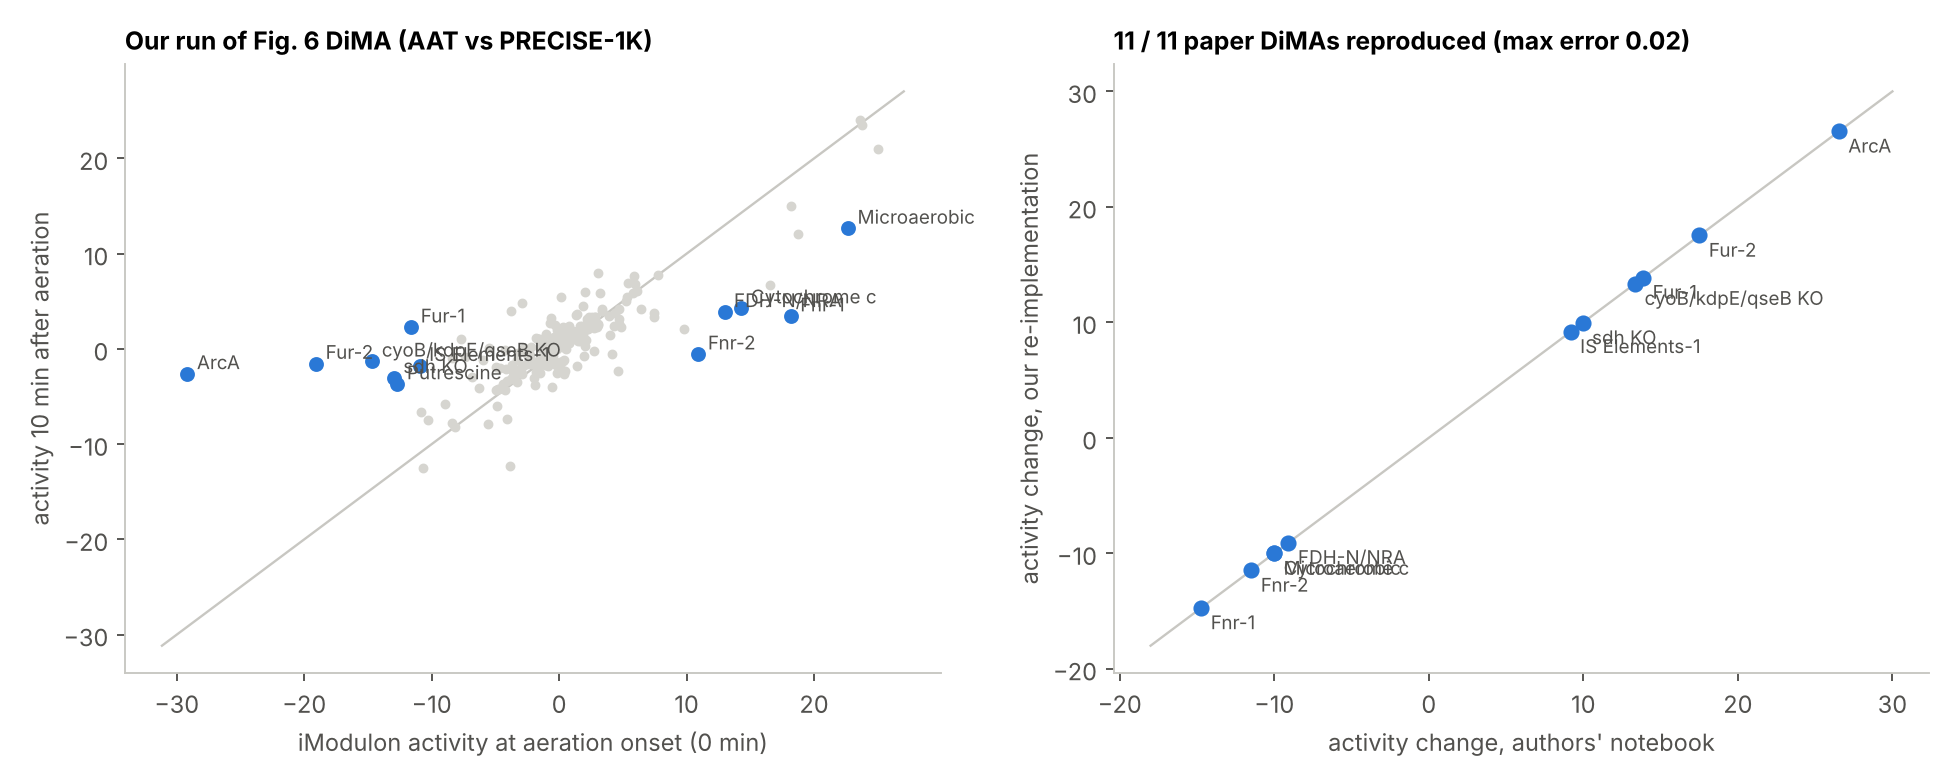

In [3]:
display(Image(A6/'fig_a6_aat_reproduction.png'))

## 2 · The perturbation interface
`Perturbation.apply(circuit_model) -> modified_circuit_model` is the contract Student B's `screen_runner` uses.

In [4]:
from perturbation import load_perturbations, GeneKnockout
from ssa_simulator import StochasticCircuit
model = yaml.safe_load(open(ROOT/'outputs/a5/calibrated_circuit_model.yaml'))
m2 = GeneKnockout('crp').apply(model)
print(m2['name']); print(m2['genetics']); print({k: m2['perturbation'][k] for k in ('kind','glucose_uM','crp_knockout','deleted_genes')})
for p, c, m in load_perturbations(ROOT/'config/precise1k_condition_map.yaml', with_controls=True):
    print(f"{p.name:24s} {p.kind:38s} matched: {m['control'] + ' -> ' + m['perturbed'] if m else '-'}")

crp_lac_circuit_A5_calibrated__dcrp
{'deleted_genes': ['crp'], 'crp_knockout': True}
{'kind': 'GeneKnockout', 'glucose_uM': 0.0, 'crp_knockout': True, 'deleted_genes': ['crp']}
glucose_to_glycerol      CarbonSourceShift                      matched: control:wt_glc -> crp:wt_glyc
glucose_to_acetate       CarbonSourceShift                      matched: control:wt_glc -> cra_crp:wt_ac
dcrp_glucose             CarbonSourceShift+GeneKnockout         matched: control:wt_glc -> crp:delcrp_glc
dcrp_glycerol            CarbonSourceShift+GeneKnockout         matched: crp:wt_glyc -> crp:delcrp_glyc
dcyaA_LB                 CarbonSourceShift+GeneKnockout         matched: raman:wt -> raman:del_cyaA
dcyaA_LB_stationary      CarbonSourceShift+GeneKnockout         matched: cyt_supp:wt -> cyt_supp:del_cyaA
IPTG_50uM_glucose        CarbonSourceShift+InducerLevelChange   matched: metb_promisc:pORF1 -> metb_promisc:pORF1_iptg
IPTG_50uM_glucose_svi3   CarbonSourceShift+InducerLevelChange   matched: metb_pr

## 3 · Simulated vs matched real conditions

In [5]:
import a6_dima_compare
df, S = a6_dima_compare.main()
S[['perturbation','held_out','real_dimas_default','sim_dimas_default','ceiling_recovered_default','r_sim_vs_ceiling',
   'panel_real_dimas','panel_recovered','panel_r','panel_sign_agreement','gene_r','gene_sign_agreement_moved']].round(2)

,perturbation,held_out,real_dimas_default,sim_dimas_default,ceiling_recovered_default,r_sim_vs_ceiling,panel_real_dimas,panel_recovered,panel_r,panel_sign_agreement,gene_r,gene_sign_agreement_moved
0,glucose_to_glycerol,False,15,0,0,0.66,7,2,0.39,1.00,0.33,0.91
1,glucose_to_acetate,False,23,0,0,0.81,10,3,0.96,1.00,0.48,0.92
2,dcrp_glucose,False,24,0,0,0.79,4,1,0.94,0.91,0.44,1.00
3,dcrp_glycerol,False,42,0,0,0.84,11,4,0.90,1.00,0.49,0.94
4,dcyaA_LB,True,46,0,0,0.74,10,4,0.70,1.00,0.39,1.00
5,dcyaA_LB_stationary,True,62,0,0,0.11,6,2,0.36,0.43,0.53,0.57
6,IPTG_50uM_glucose,True,1,0,0,0.73,0,0,0.52,0.50,0.76,1.00
7,IPTG_50uM_glucose_svi3,True,2,0,0,0.60,0,0,-0.26,0.50,0.55,1.00


**Genome-wide readout (exactly Fig. 6).** No simulated perturbation reaches a DiMA, and neither does the *ceiling*
(the real changes of the circuit's own genes, everything else held at the control). The circuit makes 27 of PRECISE-1K's 4,257
genes, so through the genome-wide pseudoinverse it can move activities by only a few units. Within that limit the simulator
follows the ceiling closely (median r ≈ 0.7).

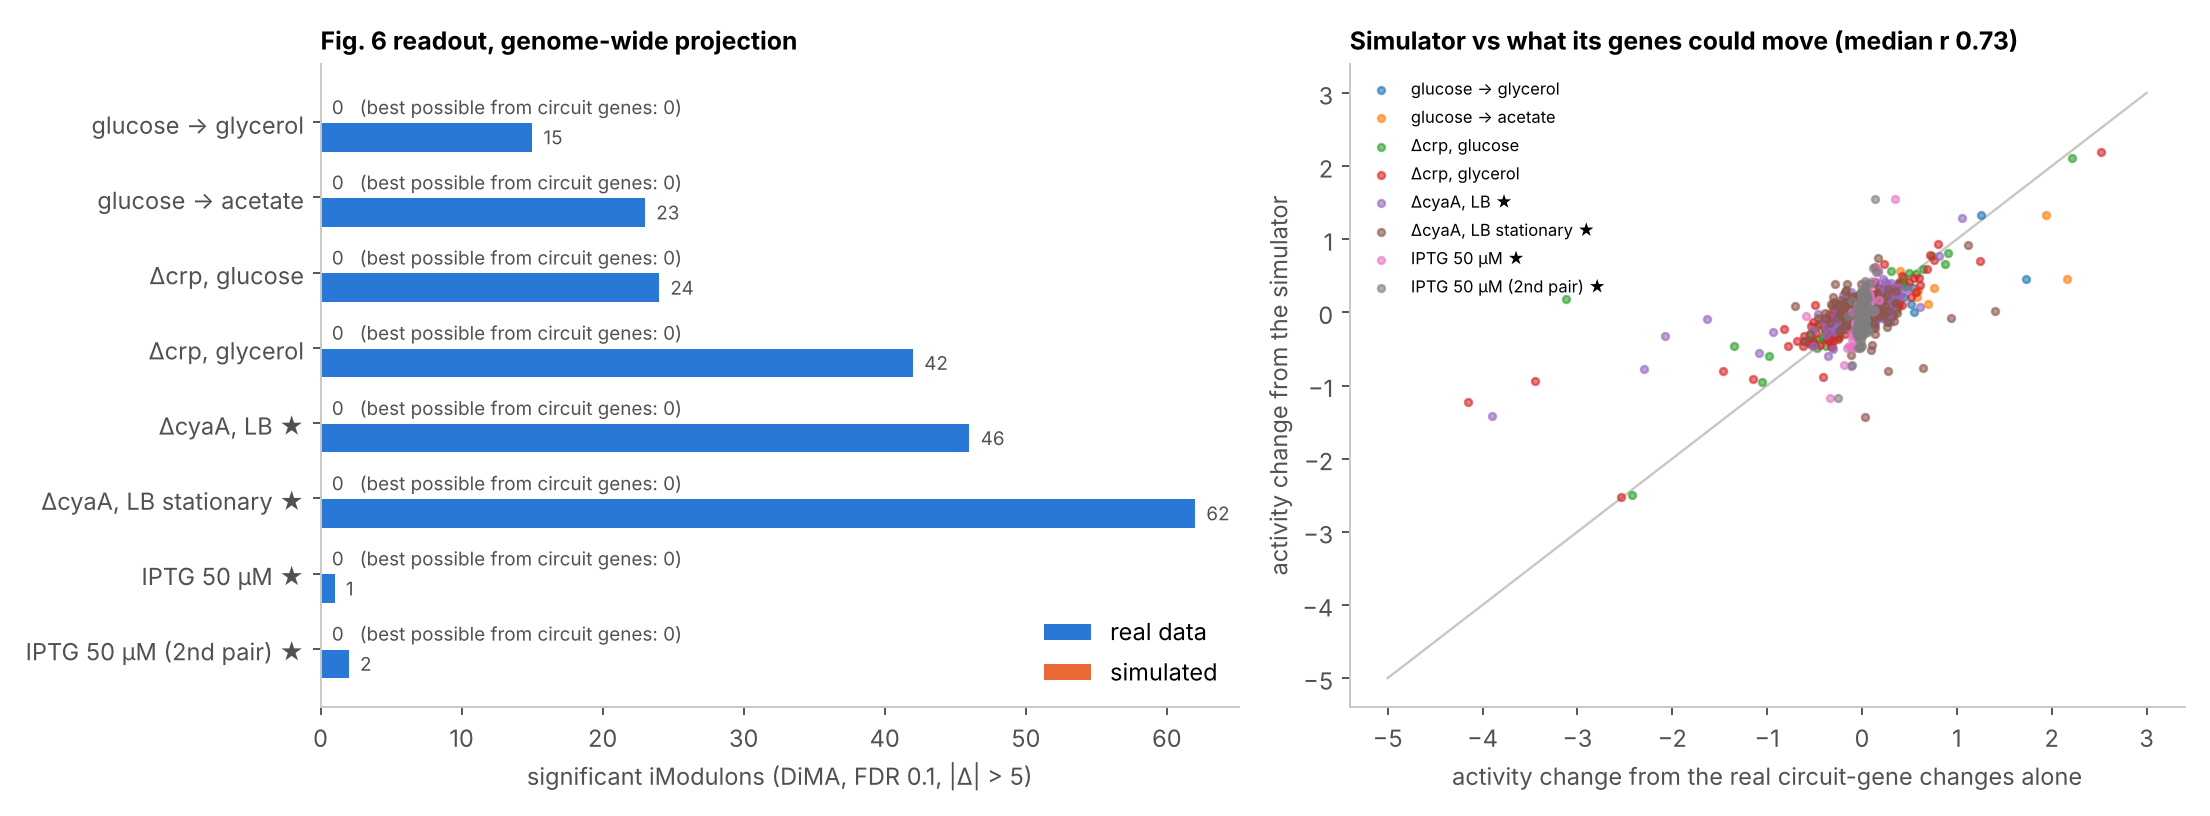

In [6]:
display(Image(A6/'fig_a6_genomewide.png'))

**Circuit-gene panel readout.** The same samples, with the activity of each iModulon read from its circuit member genes
only (kept if that reading correlates ≥ 0.5 with the full activity across PRECISE-1K). The real data, analysed the same way,
gives the target.

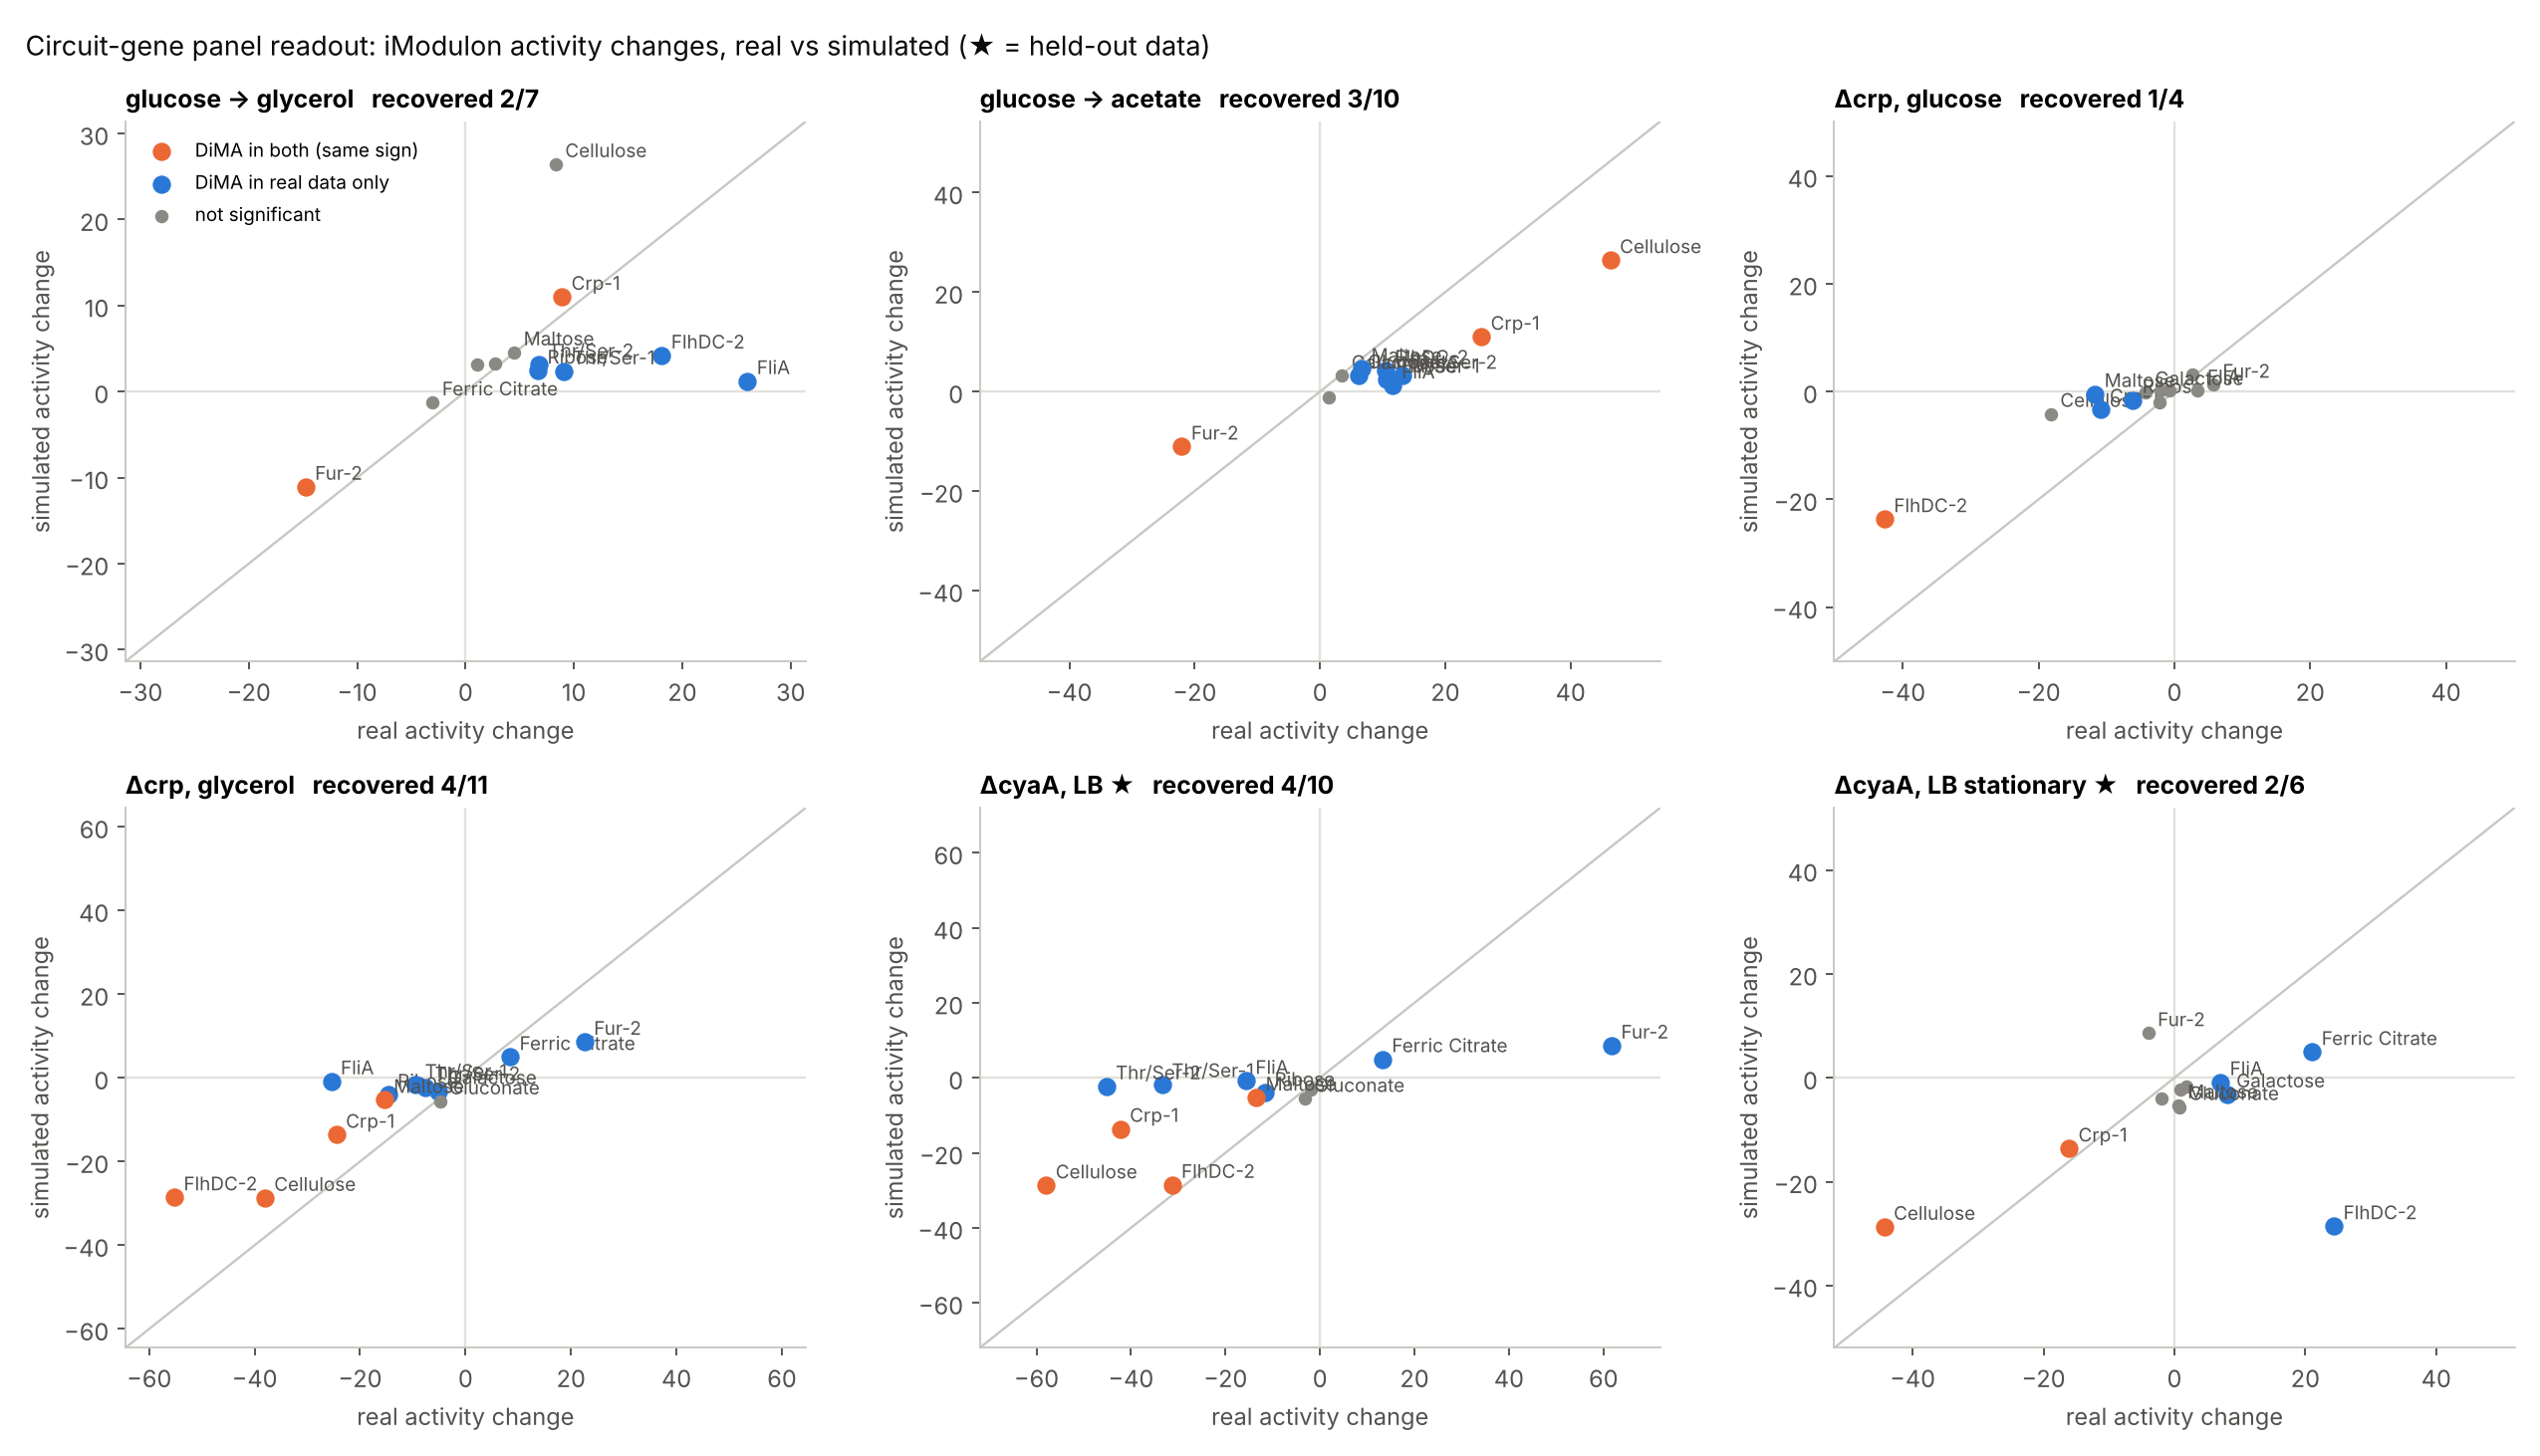

In [7]:
display(Image(A6/'fig_a6_panel_dima.png'))

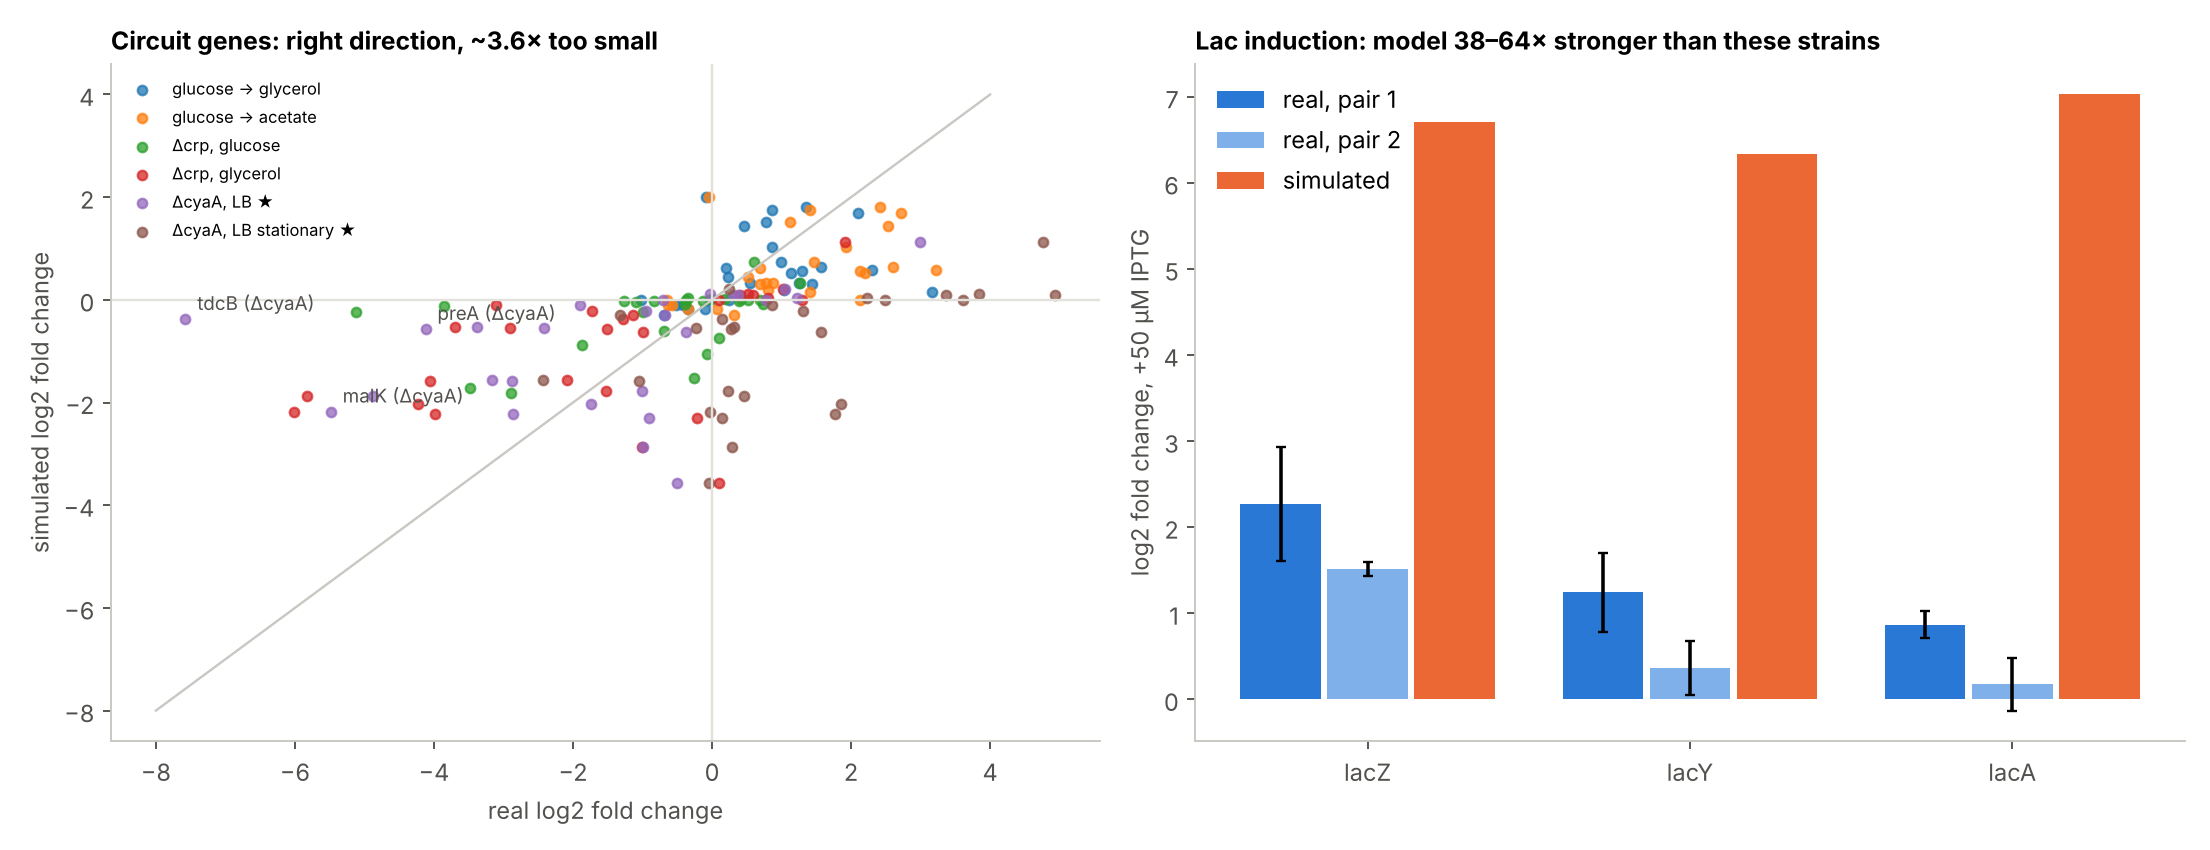

In [8]:
display(Image(A6/'fig_a6_gene_level.png'))

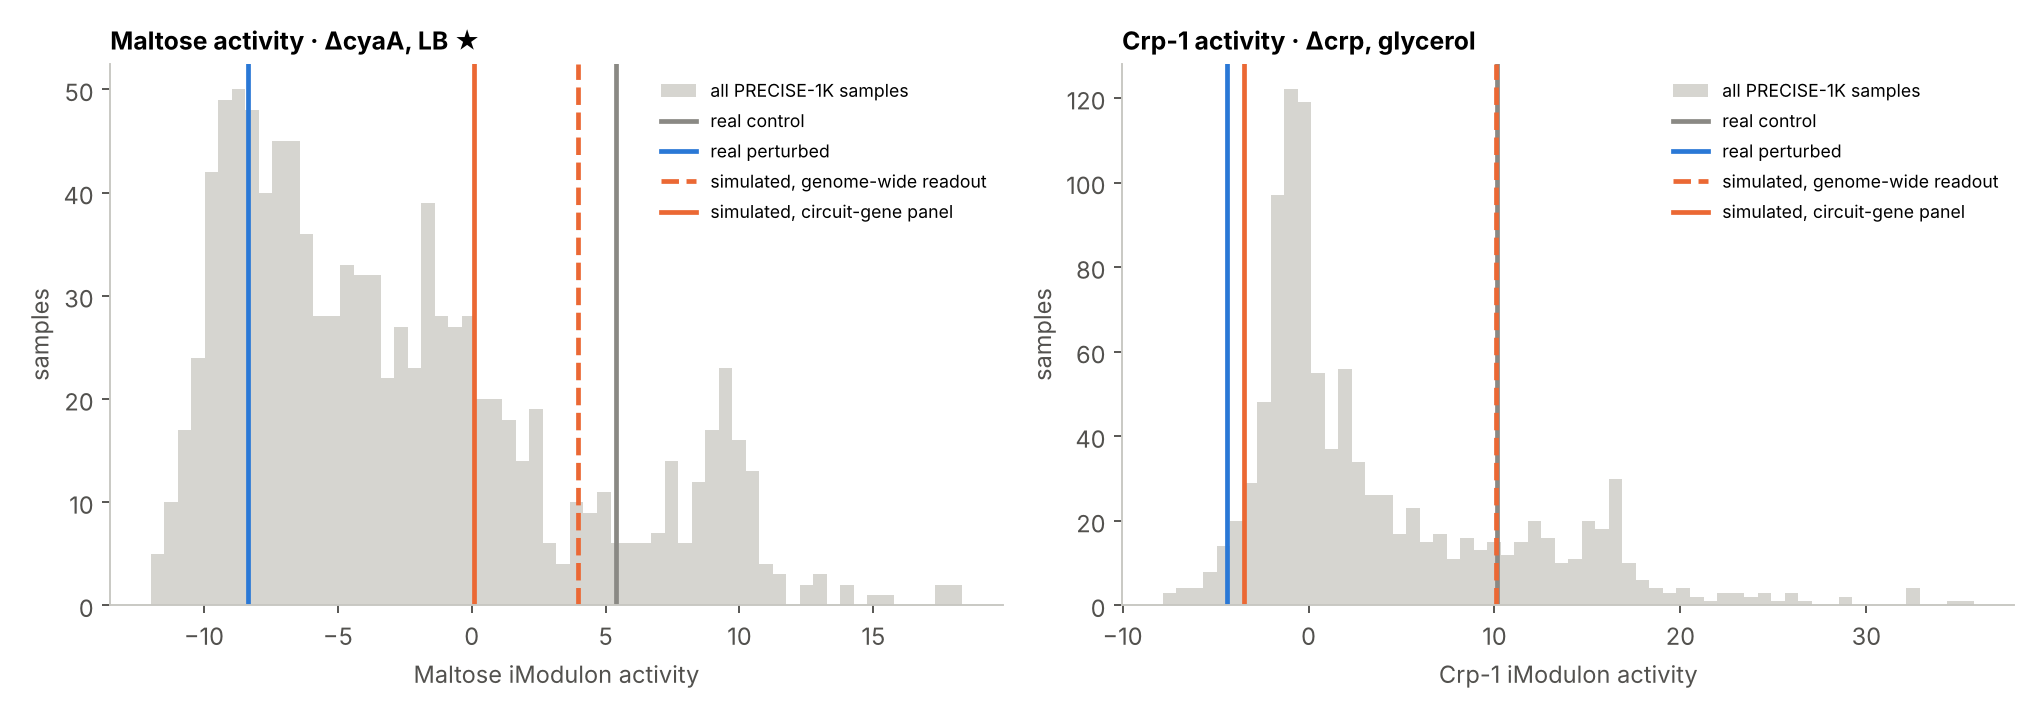

In [9]:
display(Image(A6/'fig_a6_activity_histograms.png'))

In [10]:
pd.read_csv(A6/'perturbation_dima_comparison.csv').query("imodulon in ['Crp-1','Crp-2','Maltose','FlhDC-2','crp KO-1']")[
    ['perturbation','imodulon','real_activity_control','real_activity_perturbed','sim_activity_perturbed','real_difference','sim_difference','ceiling_difference']].round(1).head(20)

,perturbation,imodulon,real_activity_control,real_activity_perturbed,sim_activity_perturbed,real_difference,sim_difference,ceiling_difference
4,glucose_to_glycerol,FlhDC-2,-0.0,20.2,0.1,20.2,0.1,0.2
81,glucose_to_glycerol,crp KO-1,0.0,-10.0,-0.1,-10.0,-0.1,-0.2
92,glucose_to_glycerol,Crp-1,-0.0,10.1,0.3,10.1,0.3,0.2
134,glucose_to_glycerol,Crp-2,0.0,7.3,0.2,7.3,0.2,0.4
179,glucose_to_glycerol,Maltose,0.0,4.3,1.3,4.3,1.3,1.3
205,glucose_to_acetate,FlhDC-2,-0.0,4.3,0.1,4.3,0.1,0.2
282,glucose_to_acetate,crp KO-1,0.0,-9.3,-0.1,-9.3,-0.1,-0.4
293,glucose_to_acetate,Crp-1,-0.0,16.3,0.3,16.3,0.3,0.6
335,glucose_to_acetate,Crp-2,0.0,8.4,0.2,8.4,0.2,0.6
380,glucose_to_acetate,Maltose,0.0,6.5,1.3,6.5,1.3,1.9
